# **Assignment 10**

---

## **Import External Libraries**

In [1]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt

from IPython.display import display, Math

from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, transpile
from qiskit.circuit.library import SwapGate, QFTGate, UGate, CUGate, HGate, CXGate
from qiskit.quantum_info import Operator, Statevector
from qiskit.visualization.bloch import Bloch
from qiskit_aer import AerSimulator
from qiskit_ibm_runtime.fake_provider import FakeMarrakesh

In [2]:
# --- Shared helpers: qubit order |q_{n-1} ... q_1 q_0>, MSB = first tensor factor (IBM-Q convention) ---
def latex_matrix(M):
    """LaTeX for a numeric array: rounded to 4 d.p., whole numbers shown as integers."""
    M = np.round(np.asarray(M, dtype=complex), 4) + 0.0
    def entry(v):
        re, im = float(v.real), float(v.imag)
        re = sp.Integer(int(re)) if re.is_integer() else sp.Float(re, 4)
        im = sp.Integer(int(im)) if im.is_integer() else sp.Float(im, 4)
        return re + sp.I * im
    return sp.latex(sp.Matrix([[entry(v) for v in row] for row in np.atleast_2d(M)]))


def ket(bits):
    """Basis column vector |bits>, e.g. ket("01") = (0, 1, 0, 0)."""
    v = np.zeros(2 ** len(bits), dtype=complex)
    v[int(bits, 2)] = 1
    return v


def kron(*ms):
    out = np.array([[1.0 + 0j]])
    for m in ms:
        out = np.kron(out, m)
    return out


I2 = np.eye(2)
X  = np.array([[0, 1], [1, 0]], dtype=complex)
Y  = np.array([[0, -1j], [1j, 0]])
Z  = np.array([[1, 0], [0, -1]], dtype=complex)
H  = np.array([[1, 1], [1, -1]]) / np.sqrt(2)
P0 = np.array([[1, 0], [0, 0]])   # |0><0|
P1 = np.array([[0, 0], [0, 1]])   # |1><1|

CNOT = kron(P0, I2) + kron(P1, X)   # control = MSB q1, target = LSB q0
SWAP = np.array([[1, 0, 0, 0], [0, 0, 1, 0], [0, 1, 0, 0], [0, 0, 0, 1]], dtype=complex)


def cps(phi):
    """Controlled phase shift U_{CPS, phi} = diag(1, 1, 1, e^{i phi}) (symmetric in its two qubits)."""
    return np.diag([1, 1, 1, np.exp(1j * phi)])


def qft_matrix(N):
    """U_QFT for ANY dimension N:  (U)_{kj} = omega^{-kj} / sqrt(N),  omega = e^{i 2 pi / N}."""
    k, j = np.meshgrid(np.arange(N), np.arange(N), indexing="ij")
    return np.exp(-2j * np.pi * k * j / N) / np.sqrt(N)


def iqft_matrix(N):
    """U_IQFT: same form with the opposite sign in the exponent,  (U)_{kj} = omega^{+kj} / sqrt(N)."""
    return qft_matrix(N).conj()


def qft_circuit(n, sign=-1, name="QFT"):
    """The lecture's n-qubit QFT circuit (Pic. 37, 38, 40). MSB = q_{n-1}, drawn at the bottom as on IBM-Q.
    Each qubit, from the MSB down, gets H and then U_{CPS, sign 2 pi / 2^j} (j = 2 ... ) controlled by the lower
    qubits; the swaps at the end reverse the qubit order. sign = -1 is QFT, sign = +1 is the 'negated phase' IQFT."""
    qc = QuantumCircuit(n, name=name)
    for t in range(n - 1, -1, -1):                     # target qubit, MSB first
        qc.h(t)
        for j, c in enumerate(range(t - 1, -1, -1), start=2):
            qc.cp(sign * 2 * np.pi / 2 ** j, c, t)     # U_{CPS, -2 pi / 2^j}
    for a in range(n // 2):
        qc.swap(a, n - 1 - a)
    return qc


# Simulators: ideal, and with the noise model of IBM's ibm_marrakesh (a snapshot of its calibration)
SHOTS   = 1024
SEED    = 2110515
ideal   = AerSimulator(seed_simulator=SEED)
backend = FakeMarrakesh()
noisy   = AerSimulator.from_backend(backend, seed_simulator=SEED)


def run(qc, sim):
    tqc = transpile(qc, sim, optimization_level=1, seed_transpiler=SEED)
    return sim.run(tqc, shots=SHOTS).result().get_counts()


def report(cnt, label, nbits):
    print(label)
    for k in range(2 ** nbits):
        key = format(k, f"0{nbits}b")
        print(f"  {key}:  {cnt.get(key, 0):4d} / {SHOTS}")


def histograms(panels, filename, nbits, ncols=None):
    """One horizontal histogram per panel; each panel = (title, ideal counts, noisy counts)."""
    ncols = ncols or len(panels)
    nrows = -(-len(panels) // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.2 * ncols, 0.8 + 0.3 * 2 ** nbits * nrows), squeeze=False)
    keys = [format(k, f"0{nbits}b") for k in range(2 ** nbits)][::-1]
    y = np.arange(len(keys))
    for ax, (title, ci, cn) in zip(axes.flat, panels):
        ax.barh(y + 0.2, [ci.get(k, 0) for k in keys], height=0.4, color="#6fa8dc", label="ideal")
        ax.barh(y - 0.2, [cn.get(k, 0) for k in keys], height=0.4, color="#e69138", label="noisy (ibm_marrakesh)")
        ax.set_yticks(y, keys)
        ax.set_xlim(0, SHOTS)
        ax.set_xlabel("Frequency")
        ax.set_ylabel("Measurement outcome")
        ax.set_title(title)
        ax.grid(axis="x", alpha=0.4)
    for ax in list(axes.flat)[len(panels):]:
        ax.axis("off")
    fig.tight_layout()
    handles, labels = axes.flat[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", ncol=2, fontsize=8, bbox_to_anchor=(0.5, 0.0))
    fig.savefig(f"../images/{filename}", dpi=200, bbox_inches="tight")
    display(fig)
    plt.close(fig)


def save_circuit(qc, filename, **kw):
    fig = qc.draw("mpl", **kw)
    fig.savefig(f"../images/{filename}", dpi=200, bbox_inches="tight")
    display(fig)
    plt.close(fig)


# --- Bloch sphere: |psi> = cos(theta/2) e^{-i phi/2} |0> + sin(theta/2) e^{i phi/2} |1>  <->  (sin t cos p, sin t sin p, cos t)
def bloch_vector(psi):
    """Bloch vector (<sigma_x>, <sigma_y>, <sigma_z>) of a normalised single-qubit state."""
    psi = np.asarray(psi, dtype=complex)
    return np.real([psi.conj() @ P @ psi for P in (X, Y, Z)])


def U3(theta, phi, lam):
    """Single-qubit arbitrary unitary U_{theta, phi, lambda} (lecture / IBM-Q definition)."""
    return np.array([[np.cos(theta / 2), -np.exp(1j * lam) * np.sin(theta / 2)],
                     [np.exp(1j * phi) * np.sin(theta / 2), np.exp(1j * (lam + phi)) * np.cos(theta / 2)]])


def Rz(a):
    return np.array([[np.cos(a), -np.sin(a), 0], [np.sin(a), np.cos(a), 0], [0, 0, 1]])


def Ry(a):
    return np.array([[np.cos(a), 0, np.sin(a)], [0, 1, 0], [-np.sin(a), 0, np.cos(a)]])


def new_bloch(ax, title=""):
    b = Bloch(axes=ax, font_size=13)
    b.xlabel = [r"$x$" + "\n" + r"$|+\rangle$", r"$|-\rangle$"]
    b.ylabel = [r"$y$" + "\n" + r"$|{+i}\rangle$", r"$|{-i}\rangle$"]
    b.zlabel = [r"$z$" + "\n" + r"$|0\rangle$", r"$|1\rangle$"]
    b.vector_color = ["#cc0000", "#3d85c6", "#38761d", "#e69138", "#674ea7", "#000000"]
    b.vector_width = 3
    b.point_color = ["#cc0000", "#3d85c6", "#38761d", "#e69138"]
    b.point_marker = ["o"]
    b.point_size = [6]
    return b


def bloch_figure(spheres, filename):
    """spheres = list of (title, vectors, paths, annotations); paths = lists of 3D points drawn as lines."""
    fig = plt.figure(figsize=(4.2 * len(spheres), 4.6))
    for i, (title, vectors, paths, notes) in enumerate(spheres):
        ax = fig.add_subplot(1, len(spheres), i + 1, projection="3d")
        b = new_bloch(ax)
        for path in paths:
            b.add_points(np.asarray(path).T, meth="l")
        if vectors:
            b.add_vectors(vectors)
        for v, text in notes:
            b.add_annotation(v, text, fontsize=11)
        b.render()
        ax.set_title(title, fontsize=13, y=-0.06)
    fig.canvas.draw()                        # the 3-D arrows need one draw before the tight bounding box
    fig.savefig(f"../images/{filename}", dpi=200, bbox_inches="tight")
    display(fig)
    plt.close(fig)

---

## **1. Discrete Fourier Transform Definition**

In [3]:
# --- Problem 1: row k of  Y = Omega X  is  y_k = (1/sqrt N) sum_j omega^{-kj} x_j ---
N_, kk, jj = sp.symbols("N k j", integer=True, positive=True)
xs = sp.symbols("x0:4")
Nn = 4
w = sp.exp(2 * sp.pi * sp.I / Nn)
Omega = sp.Matrix(Nn, Nn, lambda k, j: w ** (-k * j)) / sp.sqrt(Nn)
Ysym = Omega * sp.Matrix(xs)
for k in range(Nn):
    by_sum = sum(w ** (-k * j) * xs[j] for j in range(Nn)) / sp.sqrt(Nn)
    display(Math(f"y_{k} = " + sp.latex(sp.expand(Ysym[k]))))
    assert sp.simplify(Ysym[k] - by_sum) == 0

rng = np.random.default_rng(SEED)
for N in (2, 3, 5, 8, 16):
    x = rng.normal(size=N) + 1j * rng.normal(size=N)
    by_matrix = qft_matrix(N) @ x
    by_sum = np.array([sum(np.exp(-2j * np.pi * k * j / N) * x[j] for j in range(N)) for k in range(N)]) / np.sqrt(N)
    print(f"Problem 1  --  N = {N:2d}:  Omega x == Eq.(2) ? {np.allclose(by_matrix, by_sum)},"
          f"  == numpy.fft.fft(x, norm='ortho') ? {np.allclose(by_matrix, np.fft.fft(x, norm='ortho'))}")

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Problem 1  --  N =  2:  Omega x == Eq.(2) ? True,  == numpy.fft.fft(x, norm='ortho') ? True
Problem 1  --  N =  3:  Omega x == Eq.(2) ? True,  == numpy.fft.fft(x, norm='ortho') ? True
Problem 1  --  N =  5:  Omega x == Eq.(2) ? True,  == numpy.fft.fft(x, norm='ortho') ? True
Problem 1  --  N =  8:  Omega x == Eq.(2) ? True,  == numpy.fft.fft(x, norm='ortho') ? True
Problem 1  --  N = 16:  Omega x == Eq.(2) ? True,  == numpy.fft.fft(x, norm='ortho') ? True


---

## **2. Hermiticity of Quantum Fourier Transform**

In [4]:
# --- Problem 2: U_QFT is symmetric and unitary, but NOT Hermitian for N > 2 ---
print(f"{'N':>3} {'symmetric':>10} {'Hermitian':>10} {'unitary':>8}   eigenvalues (rounded)")
for N in range(1, 9):
    U = qft_matrix(N)
    ev = np.round(np.linalg.eigvals(U), 6)
    ev = sorted({complex(e.real + 0.0, e.imag + 0.0) for e in ev}, key=lambda e: (e.real, e.imag))
    print(f"{N:>3} {str(np.allclose(U, U.T)):>10} {str(np.allclose(U, U.conj().T)):>10} "
          f"{str(np.allclose(U.conj().T @ U, np.eye(N))):>8}   {ev}")
U4 = qft_matrix(4)
print("\nN = 4:  U^2 = (k -> -k mod N) permutation ?",
      np.allclose(U4 @ U4, np.eye(4)[[0, 3, 2, 1]]), ",  U^4 == I ?", np.allclose(np.linalg.matrix_power(U4, 4), np.eye(4)))
print("N = 2:  U_QFT == H ?", np.allclose(qft_matrix(2), H))

  N  symmetric  Hermitian  unitary   eigenvalues (rounded)
  1       True       True     True   [(1+0j)]
  2       True       True     True   [(-1+0j), (1+0j)]
  3       True      False     True   [(-1+0j), -1j, (1+0j)]
  4       True      False     True   [(-1+0j), -1j, (1+0j)]
  5       True      False     True   [(-1+0j), -1j, 1j, (1+0j)]
  6       True      False     True   [(-1+0j), -1j, 1j, (1+0j)]
  7       True      False     True   [(-1+0j), -1j, 1j, (1+0j)]
  8       True      False     True   [(-1+0j), -1j, 1j, (1+0j)]

N = 4:  U^2 = (k -> -k mod N) permutation ? True ,  U^4 == I ? True
N = 2:  U_QFT == H ? True


---

## **3. Unitarity of Quantum Fourier Transform**

In [5]:
# --- Problem 3: rows r_k = (omega^{-k0}, ..., omega^{-k(N-1)}) / sqrt N are orthonormal ---
for N in (2, 3, 4, 5, 8, 16):
    U = qft_matrix(N)
    gram = np.array([[np.vdot(U[k], U[l]) for l in range(N)] for k in range(N)])   # <r_k | r_l>
    print(f"Problem 3  --  N = {N:2d}:  <r_k|r_l> == delta_kl ? {np.allclose(gram, np.eye(N))},"
          f"  U U^dagger == I ? {np.allclose(U @ U.conj().T, np.eye(N))},  U^dagger U == I ? {np.allclose(U.conj().T @ U, np.eye(N))}")

# the geometric sum behind it:  sum_j omega^{m j} = N if m = 0 (mod N), else 0
N = 8
print("\nN = 8:  sum_j omega^{mj} for m = 0..7 :",
      [float(round(abs(sum(np.exp(2j * np.pi * m * j / N) for j in range(N))), 10)) for m in range(N)])

Problem 3  --  N =  2:  <r_k|r_l> == delta_kl ? True,  U U^dagger == I ? True,  U^dagger U == I ? True
Problem 3  --  N =  3:  <r_k|r_l> == delta_kl ? True,  U U^dagger == I ? True,  U^dagger U == I ? True
Problem 3  --  N =  4:  <r_k|r_l> == delta_kl ? True,  U U^dagger == I ? True,  U^dagger U == I ? True
Problem 3  --  N =  5:  <r_k|r_l> == delta_kl ? True,  U U^dagger == I ? True,  U^dagger U == I ? True
Problem 3  --  N =  8:  <r_k|r_l> == delta_kl ? True,  U U^dagger == I ? True,  U^dagger U == I ? True
Problem 3  --  N = 16:  <r_k|r_l> == delta_kl ? True,  U U^dagger == I ? True,  U^dagger U == I ? True

N = 8:  sum_j omega^{mj} for m = 0..7 : [8.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]


---

## **4. Construction of U_QFT**

In [6]:
# --- Problem 4: the 3-qubit U_QFT,  N = 2^3 = 8,  omega = e^{i pi/4},  (U)_{kj} = omega^{-kj} / sqrt 8 ---
N = 8
expo = (-np.outer(np.arange(N), np.arange(N))) % N           # omega^{-kj} = omega^{(-kj) mod 8}
display(Math(r"U_{QFT} = \tfrac{1}{\sqrt{8}}\,\big[\omega^{\,(-kj) \bmod 8}\big],\ \text{exponents} = " + sp.latex(sp.Matrix(expo))))
w8 = sp.exp(sp.I * sp.pi / 4)
U_exact = sp.Matrix(N, N, lambda k, j: sp.nsimplify(sp.expand_complex(w8 ** int(expo[k, j]))))
display(Math(r"\sqrt{8}\,U_{QFT} = " + sp.latex(U_exact)))
print("Problem 4  --  matches qft_matrix(8) ?", np.allclose(np.array(U_exact, dtype=complex) / np.sqrt(8), qft_matrix(8)))
print("Problem 4  --  unitary ?", np.allclose(qft_matrix(8).conj().T @ qft_matrix(8), np.eye(8)))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Problem 4  --  matches qft_matrix(8) ? True
Problem 4  --  unitary ? True


---

## **5. Inverse Quantum Fourier Transform 1**

In [7]:
# --- Problem 5: U_IQFT U_QFT = U_QFT U_IQFT = I,  U_IQFT = U_QFT^dagger ---
for N in (2, 3, 4, 5, 8, 16):
    Q, Qi = qft_matrix(N), iqft_matrix(N)
    print(f"Problem 5  --  N = {N:2d}:  U_IQFT U_QFT == I ? {np.allclose(Qi @ Q, np.eye(N))},"
          f"  U_QFT U_IQFT == I ? {np.allclose(Q @ Qi, np.eye(N))},  U_IQFT == U_QFT^dagger ? {np.allclose(Qi, Q.conj().T)}")

Problem 5  --  N =  2:  U_IQFT U_QFT == I ? True,  U_QFT U_IQFT == I ? True,  U_IQFT == U_QFT^dagger ? True
Problem 5  --  N =  3:  U_IQFT U_QFT == I ? True,  U_QFT U_IQFT == I ? True,  U_IQFT == U_QFT^dagger ? True
Problem 5  --  N =  4:  U_IQFT U_QFT == I ? True,  U_QFT U_IQFT == I ? True,  U_IQFT == U_QFT^dagger ? True
Problem 5  --  N =  5:  U_IQFT U_QFT == I ? True,  U_QFT U_IQFT == I ? True,  U_IQFT == U_QFT^dagger ? True
Problem 5  --  N =  8:  U_IQFT U_QFT == I ? True,  U_QFT U_IQFT == I ? True,  U_IQFT == U_QFT^dagger ? True
Problem 5  --  N = 16:  U_IQFT U_QFT == I ? True,  U_QFT U_IQFT == I ? True,  U_IQFT == U_QFT^dagger ? True


---

## **6. Inverse Quantum Fourier Transform 2**

In [8]:
# --- Problem 6: 2-qubit U_IQFT (N = 4, omega = i) and the check against Eq. (3) ---
U_qft_eq3  = sp.Matrix([[1, 1, 1, 1], [1, -sp.I, -1, sp.I], [1, -1, 1, -1], [1, sp.I, -1, -sp.I]]) / 2
U_iqft_2q  = sp.Matrix(4, 4, lambda k, j: sp.I ** (k * j)) / 2           # omega^{+kj} / sqrt 4
display(Math(r"U_{IQFT} = " + sp.latex(U_iqft_2q)))
display(Math(r"U_{IQFT}U_{QFT} = " + sp.latex(sp.simplify(U_iqft_2q * U_qft_eq3))
             + r",\quad U_{QFT}U_{IQFT} = " + sp.latex(sp.simplify(U_qft_eq3 * U_iqft_2q))))
print("Problem 6  --  U_IQFT == conj(U_QFT) == U_QFT^dagger ?", U_iqft_2q == U_qft_eq3.conjugate() == U_qft_eq3.H)

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Problem 6  --  U_IQFT == conj(U_QFT) == U_QFT^dagger ? True


---

## **7. Programming of QFT**

In [9]:
# --- Problem 7: U_QFT of arbitrary N (numpy only; runs unchanged in Google Colab) ---
def qft(N):
    """Matrix of U_QFT for an arbitrary dimension N:  U[k, j] = exp(-i 2 pi k j / N) / sqrt(N)."""
    k = np.arange(N).reshape(-1, 1)        # row index
    j = np.arange(N).reshape(1, -1)        # column index
    return np.exp(-2j * np.pi * k * j / N) / np.sqrt(N)


np.set_printoptions(precision=3, suppress=True, linewidth=150)
for N in (2, 3, 4):
    print(f"U_QFT (N = {N}) =\n{qft(N)}\n")

eq3 = np.array([[1, 1, 1, 1], [1, -1j, -1, 1j], [1, -1, 1, -1], [1, 1j, -1, -1j]]) / 2
print("N = 2 equals H ?", np.allclose(qft(2), H), "   N = 4 equals Eq. (3) ?", np.allclose(qft(4), eq3))
for N in (3, 6, 8, 16, 100, 1000):
    U = qft(N)
    x = np.random.default_rng(N).normal(size=N)
    print(f"N = {N:4d}:  unitary ? {np.allclose(U.conj().T @ U, np.eye(N))},"
          f"  U x == numpy FFT (norm='ortho') ? {np.allclose(U @ x, np.fft.fft(x, norm='ortho'))}")
for n in (1, 2, 3, 4, 5):
    print(f"n = {n} qubits:  qft(2^n) == Qiskit QFTGate(n)^dagger ? "
          f"{np.allclose(qft(2 ** n), Operator(QFTGate(n)).adjoint().data)}"
          f",  == lecture circuit (Pic. 40) ? {np.allclose(qft(2 ** n), Operator(qft_circuit(n)).data)}")

U_QFT (N = 2) =
[[ 0.707+0.j  0.707+0.j]
 [ 0.707+0.j -0.707-0.j]]

U_QFT (N = 3) =
[[ 0.577+0.j   0.577+0.j   0.577+0.j ]
 [ 0.577+0.j  -0.289-0.5j -0.289+0.5j]
 [ 0.577+0.j  -0.289+0.5j -0.289-0.5j]]

U_QFT (N = 4) =
[[ 0.5+0.j   0.5+0.j   0.5+0.j   0.5+0.j ]
 [ 0.5+0.j   0. -0.5j -0.5-0.j  -0. +0.5j]
 [ 0.5+0.j  -0.5-0.j   0.5+0.j  -0.5-0.j ]
 [ 0.5+0.j  -0. +0.5j -0.5-0.j   0. -0.5j]]

N = 2 equals H ? True    N = 4 equals Eq. (3) ? True
N =    3:  unitary ? True,  U x == numpy FFT (norm='ortho') ? True
N =    6:  unitary ? True,  U x == numpy FFT (norm='ortho') ? True
N =    8:  unitary ? True,  U x == numpy FFT (norm='ortho') ? True
N =   16:  unitary ? True,  U x == numpy FFT (norm='ortho') ? True
N =  100:  unitary ? True,  U x == numpy FFT (norm='ortho') ? True


N = 1000:  unitary ? True,  U x == numpy FFT (norm='ortho') ? True
n = 1 qubits:  qft(2^n) == Qiskit QFTGate(n)^dagger ? True,  == lecture circuit (Pic. 40) ? True
n = 2 qubits:  qft(2^n) == Qiskit QFTGate(n)^dagger ? True,  == lecture circuit (Pic. 40) ? True
n = 3 qubits:  qft(2^n) == Qiskit QFTGate(n)^dagger ? True,  == lecture circuit (Pic. 40) ? True
n = 4 qubits:  qft(2^n) == Qiskit QFTGate(n)^dagger ? True,  == lecture circuit (Pic. 40) ? True
n = 5 qubits:  qft(2^n) == Qiskit QFTGate(n)^dagger ? True,  == lecture circuit (Pic. 40) ? True


---

## **8. Quantum Fourier Transform of a Basis State**

In [10]:
# --- Problem 8: U_QFT |000> = equal superposition (3-qubit circuit of Pic. 38) ---
U8 = qft_matrix(8)
out = U8 @ ket("000")
display(Math(r"U_{QFT}\ket{000} = \tfrac{1}{\sqrt{8}}" + latex_matrix(np.sqrt(8) * out.reshape(1, -1)) + r"^{\top}"))
qc8 = qft_circuit(3)
print("Problem 8  --  circuit of Pic. 38 has the matrix U_QFT ?", np.allclose(Operator(qc8).data, U8))
print("Problem 8  --  Statevector of the circuit on |000> :", np.round(Statevector(qc8).data, 4))
print("Problem 8  --  probabilities:", {str(k): round(float(v), 4) for k, v in Statevector(qc8).probabilities_dict().items()})

<IPython.core.display.Math object>

Problem 8  --  circuit of Pic. 38 has the matrix U_QFT ? True
Problem 8  --  Statevector of the circuit on |000> : [0.354+0.j 0.354+0.j 0.354+0.j 0.354+0.j 0.354+0.j 0.354+0.j 0.354+0.j 0.354+0.j]
Problem 8  --  probabilities: {'000': 0.125, '001': 0.125, '010': 0.125, '011': 0.125, '100': 0.125, '101': 0.125, '110': 0.125, '111': 0.125}


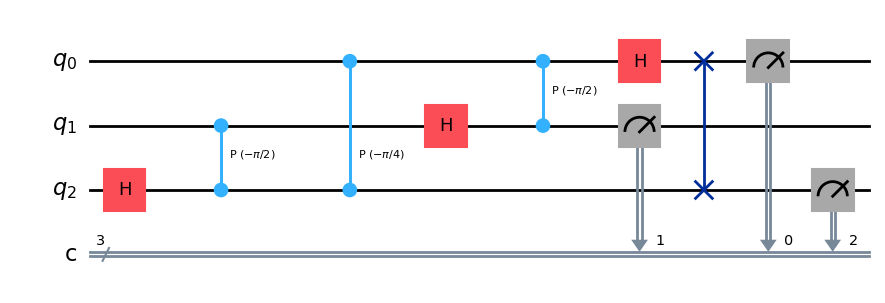

ideal
  000:   132 / 1024
  001:   135 / 1024
  010:   127 / 1024
  011:   130 / 1024
  100:   137 / 1024
  101:   138 / 1024
  110:   113 / 1024
  111:   112 / 1024
noisy (ibm_marrakesh)
  000:   133 / 1024
  001:   126 / 1024
  010:   133 / 1024
  011:   132 / 1024
  100:   139 / 1024
  101:   112 / 1024
  110:   136 / 1024
  111:   113 / 1024


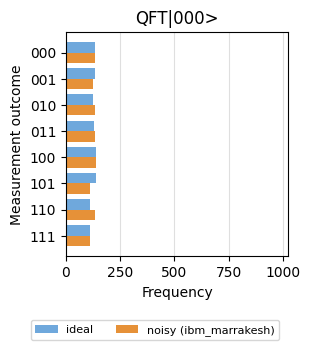

In [11]:
# --- Problem 8: run the circuit, ideal and with ibm_marrakesh noise (cf. the hardware result of Pic. 38) ---
qc = QuantumCircuit(QuantumRegister(3, "q"), ClassicalRegister(3, "c"))
qc.compose(qft_circuit(3), inplace=True)
qc.measure([0, 1, 2], [0, 1, 2])
save_circuit(qc, "problem-8-circuit.png")
ci, cn = run(qc, ideal), run(qc, noisy)
report(ci, "ideal", 3)
report(cn, "noisy (ibm_marrakesh)", 3)
histograms([("QFT|000>", ci, cn)], "problem-8-answer.png", 3)

---

## **9. Inverse of Controlled Phase Shift Gate**

In [12]:
# --- Problem 9: U_{CPS, phi} U_{CPS, -phi} = I ---
phi = sp.symbols("phi", real=True)
CPS = lambda a: sp.diag(1, 1, 1, sp.exp(sp.I * a))
display(Math(r"U_{CPS,\phi}U_{CPS,-\phi} = " + sp.latex(CPS(phi)) + sp.latex(CPS(-phi)) + " = " + sp.latex(sp.simplify(CPS(phi) * CPS(-phi)))))
print("Problem 9  --  also U_{CPS,-phi} == U_{CPS,phi}^dagger ?", sp.simplify(CPS(-phi) - CPS(phi).H) == sp.zeros(4))
for a in np.linspace(-np.pi, np.pi, 5):
    qc = QuantumCircuit(2)
    qc.cp(a, 0, 1)
    qc.cp(-a, 0, 1)
    assert np.allclose(cps(a) @ cps(-a), np.eye(4)) and np.allclose(Operator(qc).data, np.eye(4))
print("Problem 9  --  numeric check (numpy and a Qiskit cp(phi) cp(-phi) circuit), phi in {-pi, -pi/2, 0, pi/2, pi}: OK")

<IPython.core.display.Math object>

Problem 9  --  also U_{CPS,-phi} == U_{CPS,phi}^dagger ? True
Problem 9  --  numeric check (numpy and a Qiskit cp(phi) cp(-phi) circuit), phi in {-pi, -pi/2, 0, pi/2, pi}: OK


---

## **10. Inverse of SWAP Gate**

In [13]:
# --- Problem 10: SWAP SWAP = I ---
display(Math(r"U_{SWAP}U_{SWAP} = " + latex_matrix(SWAP) + latex_matrix(SWAP) + " = " + latex_matrix(SWAP @ SWAP)))
print("Problem 10  --  SWAP^2 == I ?", np.allclose(SWAP @ SWAP, np.eye(4)), ",  matches Qiskit SwapGate ?", np.allclose(Operator(SwapGate()).data, SWAP))
for b in ("00", "01", "10", "11"):
    print(f"  |{b}>  -> SWAP -> |{b[::-1]}>  -> SWAP -> |{b}>")

<IPython.core.display.Math object>

Problem 10  --  SWAP^2 == I ? True ,  matches Qiskit SwapGate ? True
  |00>  -> SWAP -> |00>  -> SWAP -> |00>
  |01>  -> SWAP -> |10>  -> SWAP -> |01>
  |10>  -> SWAP -> |01>  -> SWAP -> |10>
  |11>  -> SWAP -> |11>  -> SWAP -> |11>


---

## **11. Construction of IQFT on IBM-Q**

Problem 11  --  IQFT reversed (top): matrix == U_IQFT ? True,  IQFT . QFT == I ? True
Problem 11  --  IQFT negated phases (bottom): matrix == U_IQFT ? True,  IQFT . QFT == I ? True


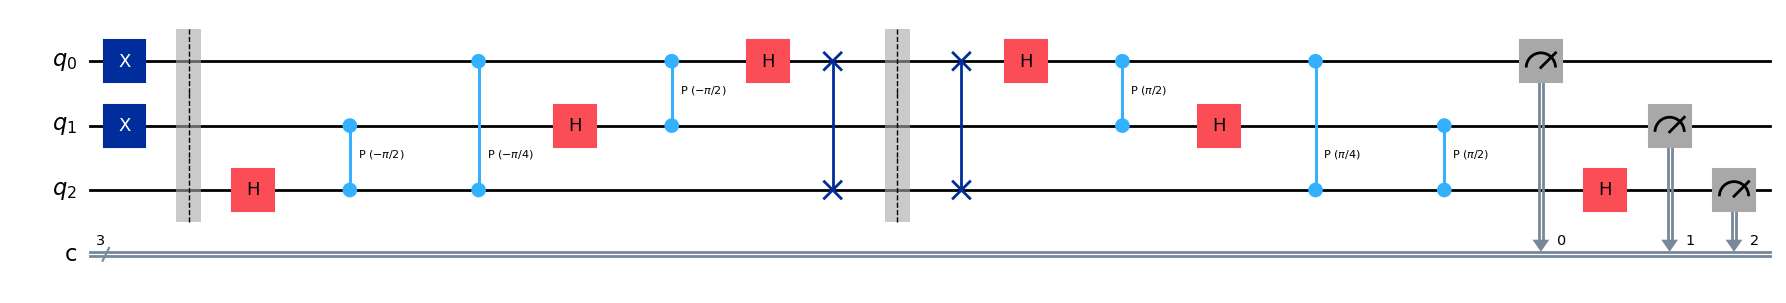

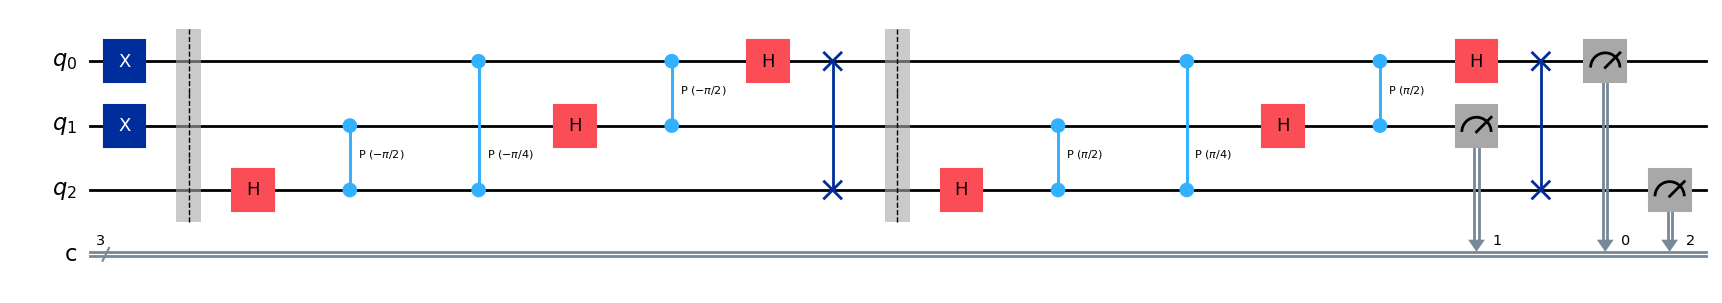

In [14]:
# --- Problem 11: the two circuits of Pic. 39 (QFT followed by IQFT) ---
def iqft_reversed(n):
    """Top of Pic. 39: the QFT circuit in reverse order with every phi -> -phi."""
    return qft_circuit(n, sign=-1).inverse()


def iqft_negated(n):
    """Bottom of Pic. 39: the same QFT circuit with every phi -> -phi."""
    return qft_circuit(n, sign=+1, name="IQFT")


for name, f in (("reversed (top)", iqft_reversed), ("negated phases (bottom)", iqft_negated)):
    print(f"Problem 11  --  IQFT {name}: matrix == U_IQFT ? {np.allclose(Operator(f(3)).data, iqft_matrix(8))},"
          f"  IQFT . QFT == I ? {np.allclose(Operator(qft_circuit(3).compose(f(3))).data, np.eye(8))}")


def pic39(bits, version):
    """X gates prepare |bits> (q2 q1 q0), then QFT, then IQFT, then measure all three qubits."""
    qc = QuantumCircuit(QuantumRegister(3, "q"), ClassicalRegister(3, "c"))
    for q, b in enumerate(reversed(bits)):
        if b == "1":
            qc.x(q)
    qc.barrier()
    qc.compose(qft_circuit(3), inplace=True)
    qc.barrier()
    qc.compose(iqft_reversed(3) if version == "top" else iqft_negated(3), inplace=True)
    qc.measure([0, 1, 2], [0, 1, 2])
    return qc


save_circuit(pic39("011", "top"), "problem-11-circuit-top.png", fold=-1)
save_circuit(pic39("011", "bottom"), "problem-11-circuit-bottom.png", fold=-1)

 input | top: ideal top: noisy | bottom: ideal bottom: noisy   (counts of the input string)


   000 |       1024        985 |          1024           979


   001 |       1024        979 |          1024           974


   010 |       1024        978 |          1024           979


   011 |       1024        978 |          1024           974


   100 |       1024        982 |          1024           979


   101 |       1024        982 |          1024           982


   110 |       1024        982 |          1024           983


   111 |       1024        981 |          1024           980


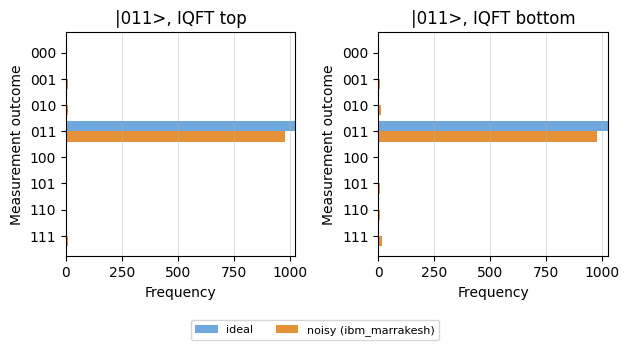

In [15]:
# --- Problem 11: every basis input (all combinations of NOT gates), both versions, ideal and noisy ---
results = {}
print(f"{'input':>6} | {'top: ideal':>10} {'top: noisy':>10} | {'bottom: ideal':>13} {'bottom: noisy':>13}   (counts of the input string)")
for k in range(8):
    bits = format(k, "03b")
    row = []
    for version in ("top", "bottom"):
        qc = pic39(bits, version)
        ci, cn = run(qc, ideal), run(qc, noisy)
        results[(bits, version)] = (ci, cn)
        row += [ci.get(bits, 0), cn.get(bits, 0)]
    print(f"{bits:>6} | {row[0]:>10} {row[1]:>10} | {row[2]:>13} {row[3]:>13}")
histograms([(f"|011>, IQFT {v}", *results[("011", v)]) for v in ("top", "bottom")], "problem-11-answer.png", 3)

---

## **12. n-Qubit QFT Circuit**

In [16]:
# --- Problem 12: gate counts and time of the n-qubit QFT circuit of Pic. 40 ---
print(f"{'n':>3} {'H':>4} {'CPS':>5} {'SWAP':>5} {'total':>6} | {'n':>3} {'n(n-1)/2':>9} {'floor(n/2)':>11} {'n(n+1)/2+floor(n/2)':>20} | {'depth':>6} {'2n':>4}")
for n in range(1, 11):
    qc = qft_circuit(n)
    ops = qc.count_ops()
    h, c, s = ops.get("h", 0), ops.get("cp", 0), ops.get("swap", 0)
    formula = n * (n + 1) // 2 + n // 2
    print(f"{n:>3} {h:>4} {c:>5} {s:>5} {h + c + s:>6} | {n:>3} {n * (n - 1) // 2:>9} {n // 2:>11} {formula:>20} | {qc.depth():>6} {2 * n if n > 1 else 1:>4}")
    assert (h, c, s) == (n, n * (n - 1) // 2, n // 2)

  n    H   CPS  SWAP  total |   n  n(n-1)/2  floor(n/2)  n(n+1)/2+floor(n/2) |  depth   2n
  1    1     0     0      1 |   1         0           0                    1 |      1    1
  2    2     1     1      4 |   2         1           1                    4 |      4    4
  3    3     3     1      7 |   3         3           1                    7 |      6    6
  4    4     6     2     12 |   4         6           2                   12 |      8    8
  5    5    10     2     17 |   5        10           2                   17 |     10   10
  6    6    15     3     24 |   6        15           3                   24 |     12   12
  7    7    21     3     31 |   7        21           3                   31 |     14   14
  8    8    28     4     40 |   8        28           4                   40 |     16   16
  9    9    36     4     49 |   9        36           4                   49 |     18   18
 10   10    45     5     60 |  10        45           5                   60 |     20   20

---

## **13. 3-Qubit QFT**

In [17]:
# --- Problem 13: U = SWAP_{q2,q0} (I I H) (I CPS_{-pi/2}) (I H I) CPS_{-pi/4}^{(q2,q0)} (CPS_{-pi/2} I) (H I I)  (exact) ---
sI, sH = sp.eye(2), sp.Matrix([[1, 1], [1, -1]]) / sp.sqrt(2)
skron = lambda *ms: sp.kronecker_product(*ms) if len(ms) > 1 else ms[0]
def scps(phi):
    return sp.diag(1, 1, 1, sp.exp(sp.I * phi))

def cps_far(phi):          # CPS between q2 (MSB) and q0 (LSB): phase on |1 x 1>
    return sp.diag(*[sp.exp(sp.I * phi) if (b >> 2) & 1 and b & 1 else 1 for b in range(8)])

swap_20 = sp.zeros(8)
for b in range(8):
    swap_20[int(format(b, "03b")[::-1], 2), b] = 1

gates = [("H \otimes I \otimes I", skron(sH, sI, sI)),
         ("U_{CPS,-\pi/2} \otimes I", skron(scps(-sp.pi / 2), sI)),
         ("U_{CPS,-\pi/4}^{(q_2, q_0)}", cps_far(-sp.pi / 4)),
         ("I \otimes H \otimes I", skron(sI, sH, sI)),
         ("I \otimes U_{CPS,-\pi/2}", skron(sI, scps(-sp.pi / 2))),
         ("I \otimes I \otimes H", skron(sI, sI, sH)),
         ("U_{SWAP}^{(q_2, q_0)}", swap_20)]
U = sp.eye(8)
for label, G in gates:
    U = G * U
U = sp.simplify(U)
display(Math(r"\sqrt{8}\,U_{QFT} = " + sp.latex((sp.sqrt(8) * U).applyfunc(lambda e: sp.nsimplify(sp.expand_complex(e))))))
U_def = sp.Matrix(8, 8, lambda k, j: sp.exp(-sp.I * sp.pi * k * j / 4)) / sp.sqrt(8)
print("Problem 13  --  gate product == definition omega^{-kj}/sqrt 8 ?", sp.simplify(U - U_def) == sp.zeros(8))

# product form of U_QFT |j2 j1 j0>:  (|0> + e^{-2 pi i 0.j0}|1>)(|0> + e^{-2 pi i 0.j1j0}|1>)(|0> + e^{-2 pi i 0.j2j1j0}|1>) / sqrt 8
for j in range(8):
    j2, j1, j0 = (j >> 2) & 1, (j >> 1) & 1, j & 1
    f = lambda frac: np.array([1, np.exp(-2j * np.pi * frac)]) / np.sqrt(2)
    prod = kron(f(j0 / 2), f(j1 / 2 + j0 / 4), f(j2 / 2 + j1 / 4 + j0 / 8)).ravel()
    assert np.allclose(prod, qft_matrix(8)[:, j])
print("Problem 13  --  product form == column j of U_QFT for every j: OK")

<IPython.core.display.Math object>

Problem 13  --  gate product == definition omega^{-kj}/sqrt 8 ? True
Problem 13  --  product form == column j of U_QFT for every j: OK


---

## **14. 7-Qubit SWAP Gate**

In [18]:
# --- Problem 14: U_{SWAP,7} = U_{SWAP,2,4} U_{SWAP,1,5} U_{SWAP,0,6} on |1001100> ---
state = list("1001100")                      # X0 X1 ... X6 (X0 written first = MSB)
print("Problem 14  --  start           :", "".join(state))
for a, b in ((0, 6), (1, 5), (2, 4)):
    state[a], state[b] = state[b], state[a]
    print(f"Problem 14  --  after SWAP_{a},{b}  :", "".join(state))

qc = QuantumCircuit(7)
for a in range(3):
    qc.swap(a, 6 - a)
out = Statevector.from_label("1001100").evolve(qc)
print("Problem 14  --  Qiskit: SWAP_7 |1001100> =", {str(k): round(float(v), 3) for k, v in out.probabilities_dict().items()})

Problem 14  --  start           : 1001100
Problem 14  --  after SWAP_0,6  : 0001101
Problem 14  --  after SWAP_1,5  : 0001101
Problem 14  --  after SWAP_2,4  : 0011001
Problem 14  --  Qiskit: SWAP_7 |1001100> = {'0011001': 1.0}


---

## **15. Effect of Global Phase on a Single Qubit**

In [19]:
# --- Problem 15: <psi'| sigma_z |psi'> with |psi'> = e^{i gamma}|psi> ---
th, ph, g = sp.symbols("theta phi gamma", real=True)
psi_s = sp.Matrix([sp.cos(th / 2) * sp.exp(-sp.I * ph / 2), sp.sin(th / 2) * sp.exp(sp.I * ph / 2)])
sz = sp.Matrix([[1, 0], [0, -1]])
psi_g = sp.exp(sp.I * g) * psi_s
ev = sp.simplify((psi_g.H * sz * psi_g)[0])
raw = (psi_g.H * sz * psi_g)[0]
display(Math(r"\bra{\psi'}\sigma_z\ket{\psi'} = " + sp.latex(sp.expand(raw)) + " = " + sp.latex(sp.trigsimp(ev))))
print("Problem 15  --  d/dgamma <psi'|Z|psi'> =", sp.diff(ev, g))
rng = np.random.default_rng(SEED)
for _ in range(3):
    v = rng.normal(size=2) + 1j * rng.normal(size=2)
    v /= np.linalg.norm(v)
    gam = rng.uniform(0, 2 * np.pi)
    print(f"Problem 15  --  gamma = {gam:.3f}:  <psi|Z|psi> = {np.real(v.conj() @ Z @ v):+.6f},"
          f"  <psi'|Z|psi'> = {np.real((np.exp(1j * gam) * v).conj() @ Z @ (np.exp(1j * gam) * v)):+.6f}")

<IPython.core.display.Math object>

Problem 15  --  d/dgamma <psi'|Z|psi'> = 0
Problem 15  --  gamma = 5.530:  <psi|Z|psi> = +0.377052,  <psi'|Z|psi'> = +0.377052
Problem 15  --  gamma = 3.552:  <psi|Z|psi> = +0.763012,  <psi'|Z|psi'> = +0.763012
Problem 15  --  gamma = 4.004:  <psi|Z|psi> = -0.579248,  <psi'|Z|psi'> = -0.579248


---

## **16. Extrema on the Bloch Sphere**

+z: theta = 0.00 pi, phi = 0.00 pi  ->  psi = ((1+0j)) |0>    Bloch = [0. 0. 1.],  sigma_z eigenvector ? True (eigenvalue +1)
-z: theta = 1.00 pi, phi = 0.00 pi  ->  psi = ((1+0j)) |1>    Bloch = [ 0.  0. -1.],  sigma_z eigenvector ? True (eigenvalue -1)
+x: theta = 0.50 pi, phi = 0.00 pi  ->  psi = ((1+0j)) |+>    Bloch = [1. 0. 0.],  sigma_x eigenvector ? True (eigenvalue +1)
-x: theta = 0.50 pi, phi = 1.00 pi  ->  psi = (-1j) |->    Bloch = [-1.  0.  0.],  sigma_x eigenvector ? True (eigenvalue -1)
+y: theta = 0.50 pi, phi = 0.50 pi  ->  psi = ((0.7071-0.7071j)) |+i>   Bloch = [0. 1. 0.],  sigma_y eigenvector ? True (eigenvalue +1)
-y: theta = 0.50 pi, phi = 1.50 pi  ->  psi = ((-0.7071-0.7071j)) |-i>   Bloch = [ 0. -1.  0.],  sigma_y eigenvector ? True (eigenvalue -1)


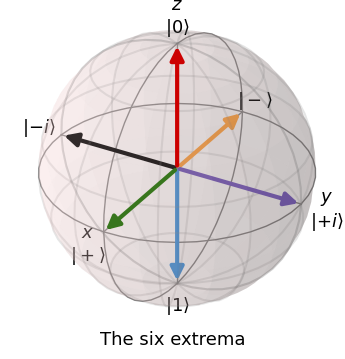

In [20]:
# --- Problem 16: the six extrema (theta, phi) and their states ---
extrema = [("+z", 0, 0), ("-z", np.pi, 0), ("+x", np.pi / 2, 0), ("-x", np.pi / 2, np.pi), ("+y", np.pi / 2, np.pi / 2), ("-y", np.pi / 2, 3 * np.pi / 2)]
named = {"|0>": np.array([1, 0]), "|1>": np.array([0, 1]), "|+>": np.array([1, 1]) / np.sqrt(2), "|->": np.array([1, -1]) / np.sqrt(2),
         "|+i>": np.array([1, 1j]) / np.sqrt(2), "|-i>": np.array([1, -1j]) / np.sqrt(2)}
pauli = {"x": X, "y": Y, "z": Z}
vecs, notes = [], []
for axis, t, p in extrema:
    psi = np.array([np.cos(t / 2) * np.exp(-1j * p / 2), np.sin(t / 2) * np.exp(1j * p / 2)])
    match = [n for n, v in named.items() if np.isclose(abs(np.vdot(v, psi)), 1)][0]
    gphase = np.vdot(named[match], psi)                                    # psi = gphase * |match>
    eig = np.real(psi.conj() @ pauli[axis[1]] @ psi)
    is_eig = np.allclose(pauli[axis[1]] @ psi, eig * psi)
    print(f"{axis}: theta = {t / np.pi:.2f} pi, phi = {p / np.pi:.2f} pi  ->  psi = ({np.round(gphase, 4)}) {match:5s}"
          f"  Bloch = {np.round(bloch_vector(psi), 4) + 0.0},  sigma_{axis[1]} eigenvector ? {is_eig} (eigenvalue {eig:+.0f})")
    vecs.append(bloch_vector(psi))
bloch_figure([("The six extrema", vecs, [], [])], "problem-16-answer.png")

---

## **17. Expectation Values of Pauli Matrices of the States on Bloch Sphere**

In [21]:
# --- Problem 17: <psi|sigma_x|psi> = sin(theta) cos(phi),  <psi|sigma_y|psi> = sin(theta) sin(phi) ---
sx = sp.Matrix([[0, 1], [1, 0]])
sy = sp.Matrix([[0, -sp.I], [sp.I, 0]])
for name, S, target in (("x", sx, sp.sin(th) * sp.cos(ph)), ("y", sy, sp.sin(th) * sp.sin(ph))):
    raw = sp.expand((psi_s.H * S * psi_s)[0])
    val = sp.simplify(sp.trigsimp(sp.expand_complex(raw)))
    display(Math(rf"\bra{{\psi}}\sigma_{name}\ket{{\psi}} = " + sp.latex(raw) + " = " + sp.latex(val)))
    print(f"Problem 17  --  equals {target} ?", sp.simplify(val - target) == 0)

<IPython.core.display.Math object>

Problem 17  --  equals sin(theta)*cos(phi) ? True


<IPython.core.display.Math object>

Problem 17  --  equals sin(phi)*sin(theta) ? True


---

## **18. State on Bloch Sphere**

Problem 18  --  |a|^2 + |b|^2 = 1
Problem 18  --  |a| = sqrt(3)/2 , arg a = -pi/6 ;  |b| = 1/2 , arg b = -pi/6
Problem 18  --  theta = pi/3 , phi = 0 , global phase e^{i gamma}, gamma = -pi/6
Problem 18  --  e^{i gamma}(cos(theta/2) e^{-i phi/2}|0> + sin(theta/2) e^{i phi/2}|1>) == psi ? True
Problem 18  --  Bloch vector (<X>, <Y>, <Z>) = [0.866 0.    0.5  ]  = (sqrt3/2, 0, 1/2) ? True


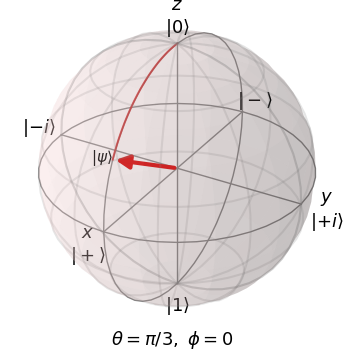

In [22]:
# --- Problem 18: |psi> = (3/4 - i sqrt3/4)|0> + (sqrt3/4 - i/4)|1> ---
a = sp.Rational(3, 4) - sp.I * sp.sqrt(3) / 4
b = sp.sqrt(3) / 4 - sp.I / 4
print("Problem 18  --  |a|^2 + |b|^2 =", sp.simplify(sp.Abs(a) ** 2 + sp.Abs(b) ** 2))
print("Problem 18  --  |a| =", sp.simplify(sp.Abs(a)), ", arg a =", sp.simplify(sp.arg(a)), ";  |b| =", sp.simplify(sp.Abs(b)), ", arg b =", sp.simplify(sp.arg(b)))
theta18 = 2 * sp.acos(sp.Abs(a))
phi18 = sp.simplify(sp.arg(b) - sp.arg(a))
gamma18 = sp.simplify((sp.arg(a) + sp.arg(b)) / 2)               # global phase
print("Problem 18  --  theta =", theta18, ", phi =", phi18, ", global phase e^{i gamma}, gamma =", gamma18)
psi18 = np.array([complex(a), complex(b)])
rebuilt = np.exp(1j * float(gamma18)) * np.array([np.cos(float(theta18) / 2) * np.exp(-1j * float(phi18) / 2),
                                                   np.sin(float(theta18) / 2) * np.exp(1j * float(phi18) / 2)])
print("Problem 18  --  e^{i gamma}(cos(theta/2) e^{-i phi/2}|0> + sin(theta/2) e^{i phi/2}|1>) == psi ?", np.allclose(rebuilt, psi18))
v18 = bloch_vector(psi18)
print("Problem 18  --  Bloch vector (<X>, <Y>, <Z>) =", np.round(v18, 4) + 0.0, " = (sqrt3/2, 0, 1/2) ?", np.allclose(v18, [np.sqrt(3) / 2, 0, 0.5]))
meridian = [Ry(t) @ [0, 0, 1] for t in np.linspace(0, float(theta18), 40)]
bloch_figure([(r"$\theta = \pi/3,\ \phi = 0$", [v18], [meridian], [(1.15 * v18, r"$|\psi\rangle$")])], "problem-18-answer.png")

---

## **19. U_{θ,φ,λ} as a Hadamard gate**

In [23]:
# --- Problem 19: match U_{theta, phi, lambda} to H element by element ---
lam = sp.symbols("lambda", real=True)
U3s = lambda t, p, l: sp.Matrix([[sp.cos(t / 2), -sp.exp(sp.I * l) * sp.sin(t / 2)],
                                 [sp.exp(sp.I * p) * sp.sin(t / 2), sp.exp(sp.I * (l + p)) * sp.cos(t / 2)]])
display(Math(r"U_{\theta,\phi,\lambda} = " + sp.latex(U3s(th, ph, lam))))
UH = U3s(sp.pi / 2, 0, sp.pi)
display(Math(r"U_{\frac{\pi}{2},0,\pi} = " + sp.latex(sp.simplify(UH))))
print("Problem 19  --  U_{pi/2, 0, pi} == H ?", sp.simplify(UH - sp.Matrix([[1, 1], [1, -1]]) / sp.sqrt(2)) == sp.zeros(2))
print("Problem 19  --  Qiskit UGate(pi/2, 0, pi) == HGate ?", np.allclose(Operator(UGate(np.pi / 2, 0, np.pi)).data, Operator(HGate()).data))
print("Problem 19  --  U|0> =", np.round(U3(np.pi / 2, 0, np.pi) @ [1, 0], 4), " U|1> =", np.round(U3(np.pi / 2, 0, np.pi) @ [0, 1], 4))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Problem 19  --  U_{pi/2, 0, pi} == H ? True
Problem 19  --  Qiskit UGate(pi/2, 0, pi) == HGate ? True
Problem 19  --  U|0> = [0.707+0.j 0.707+0.j]  U|1> = [ 0.707-0.j -0.707+0.j]


---

## **20. Rotation on Bloch Sphere by Hadamard Gate**

Problem 20  --  |+>: start [1. 0. 0.] -> after Rz(pi) [-1.  0.  0.] -> after Ry(pi/2) [0. 0. 1.];  Bloch vector of H|+> = [0. 0. 1.]  match ? True
Problem 20  --  |1>: start [ 0.  0. -1.] -> after Rz(pi) [ 0.  0. -1.] -> after Ry(pi/2) [-1.  0.  0.];  Bloch vector of H|1> = [-1.  0.  0.]  match ? True


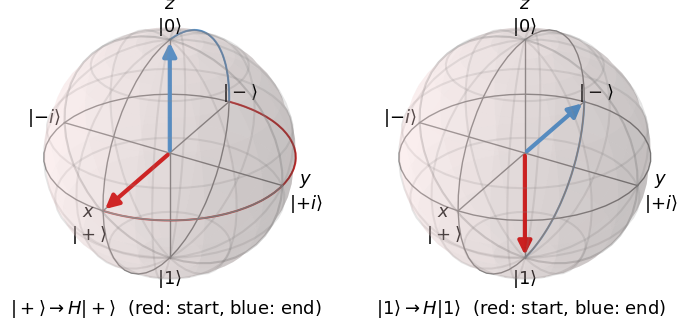

In [24]:
# --- Problem 20: H = U_{pi/2, 0, pi}: rotate about z by lambda = pi, then about y by theta = pi/2, then about z by phi = 0 ---
def euler_path(v0, theta, phi, lam, steps=40):
    """Points of the extrinsic Euler rotation Rz(phi) Ry(theta) Rz(lam) applied to the Bloch vector v0."""
    s = np.linspace(0, 1, steps)
    p1 = [Rz(lam * t) @ v0 for t in s]
    p2 = [Ry(theta * t) @ p1[-1] for t in s]
    p3 = [Rz(phi * t) @ p2[-1] for t in s]
    return p1, p2, p3, p3[-1]


spheres = []
for name, psi in (("|+>", np.array([1, 1]) / np.sqrt(2)), ("|1>", np.array([0, 1]))):
    v0 = bloch_vector(psi)
    p1, p2, p3, v_end = euler_path(v0, np.pi / 2, 0, np.pi)
    v_mid = p1[-1]
    v_true = bloch_vector(H @ psi)
    print(f"Problem 20  --  {name}: start {np.round(v0, 4) + 0.0} -> after Rz(pi) {np.round(v_mid, 4) + 0.0}"
          f" -> after Ry(pi/2) {np.round(v_end, 4) + 0.0};  Bloch vector of H{name} = {np.round(v_true, 4) + 0.0}  match ? {np.allclose(v_end, v_true)}")
    title = rf"$|{name[1:-1]}\rangle \rightarrow H|{name[1:-1]}\rangle$  (red: start, blue: end)"
    spheres.append((title, [v0, v_end], [p1, p2], []))
bloch_figure(spheres, "problem-20-answer.png")

---

## **21. Entanglement Circuit on IBM-Q**

Problem 21  --  controlled U_{pi,0,pi} (gamma = 0) == CNOT ? True
Problem 21  --  |0><0| (x) I + |1><1| (x) U_{pi,0,pi} == CNOT (control MSB) ? True
Problem 21  --  gamma = pi/2 instead gives |0><0| (x) I + i |1><1| (x) X : True
input |00> -> |Phi+>:  state = [0.707+0.j 0.   +0.j 0.   +0.j 0.707+0.j]


   ideal {'00': 524, '11': 500}   noisy {'00': 518, '01': 3, '10': 10, '11': 493}
input |01> -> |Psi+>:  state = [ 0.   +0.j  0.707+0.j  0.707-0.j -0.   +0.j]


   ideal {'01': 524, '10': 500}   noisy {'00': 9, '01': 512, '10': 496, '11': 7}
input |10> -> |Phi->:  state = [ 0.707-0.j  0.   +0.j -0.   +0.j -0.707+0.j]


   ideal {'00': 524, '11': 500}   noisy {'00': 518, '01': 3, '10': 10, '11': 493}
input |11> -> |Psi->:  state = [ 0.   -0.j  0.707-0.j -0.707+0.j  0.   -0.j]


   ideal {'01': 524, '10': 500}   noisy {'00': 9, '01': 512, '10': 496, '11': 7}


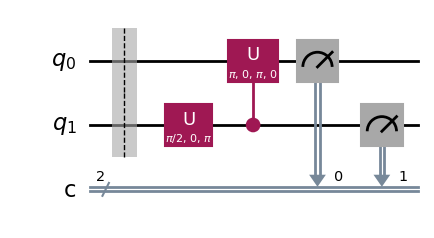

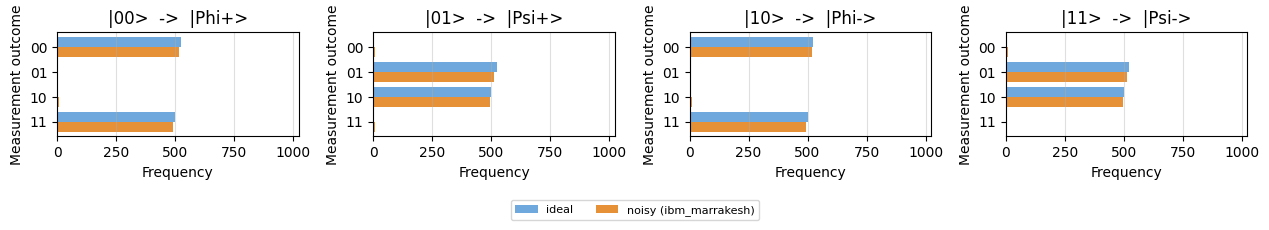

In [25]:
# --- Problem 21: Bell states with only U gates: U_{pi/2,0,pi} (= H) and controlled-U_{pi,0,pi} (= CNOT), gamma = 0 ---
CU = Operator(CUGate(np.pi, 0, np.pi, 0)).data          # Qiskit order: control = q0 here
print("Problem 21  --  controlled U_{pi,0,pi} (gamma = 0) == CNOT ?", np.allclose(CU, Operator(CXGate()).data))
print("Problem 21  --  |0><0| (x) I + |1><1| (x) U_{pi,0,pi} == CNOT (control MSB) ?",
      np.allclose(kron(P0, I2) + kron(P1, U3(np.pi, 0, np.pi)), CNOT))
print("Problem 21  --  gamma = pi/2 instead gives |0><0| (x) I + i |1><1| (x) X :",
      np.allclose(Operator(CUGate(np.pi, 0, np.pi, np.pi / 2)).data, np.kron(I2, P0) + 1j * np.kron(X, P1)))


def bell(bits):
    """Prepare |bits> with U_{pi,0,pi} (NOT), then U_{pi/2,0,pi} on q1 and controlled-U_{pi,0,pi} q1 -> q0."""
    qc = QuantumCircuit(QuantumRegister(2, "q"), ClassicalRegister(2, "c"))
    for q, b in enumerate(reversed(bits)):
        if b == "1":
            qc.u(np.pi, 0, np.pi, q)
    qc.barrier()
    qc.u(np.pi / 2, 0, np.pi, 1)
    qc.cu(np.pi, 0, np.pi, 0, 1, 0)                     # (theta, phi, lambda, gamma, control, target)
    return qc


names = {"00": r"|Phi+>", "01": r"|Psi+>", "10": r"|Phi->", "11": r"|Psi->"}
panels = []
for bits in ("00", "01", "10", "11"):
    qc = bell(bits)
    sv = Statevector(qc.remove_final_measurements(inplace=False))
    print(f"input |{bits}> -> {names[bits]}:  state = {np.round(sv.data, 4)}")
    qc.measure([0, 1], [0, 1])
    ci, cn = run(qc, ideal), run(qc, noisy)
    panels.append((f"|{bits}>  ->  {names[bits]}", ci, cn))
    print(f"   ideal {dict(sorted(ci.items()))}   noisy {dict(sorted(cn.items()))}")
qc = bell("00")
qc.measure([0, 1], [0, 1])
save_circuit(qc, "problem-21-circuit.png")
histograms(panels, "problem-21-answer.png", 2, ncols=4)

---